# Chapter 14: Optimal Bernoulli Sets (BHF)

Companion notebook for **Chapter 14** of *Bernoulli Types: Two-Sided Error in Approximate Membership, Retrieval, and Computation*. Source files: `book/chapters/ch14/`.

Chapter 8 proved that any FNR-zero approximate set at false-positive rate $\fprate$ needs at least $-\log_2 \fprate$ bits per element (`thm:entropy-floor`), and that the optimally tuned Bloom filter spends $\log_2 e \approx 1.443$ times that (`prop:bloom-overhead`). Chapter 14 answers the constructive question twice, from opposite ends, and this notebook follows both answers.

1. **The Bernoulli hash function (BHF)** of §14.2 (`def:bhf`) stores one salt and nothing else. It fixes an acceptance set $\{0, \ldots, t\}$ of density $\fprate = (t + 1)/N$ in the range of a hash $h(x, b)$ and searches the salts $b_1, b_2, \ldots$ for the first one under which every member is accepted. Its expected salt length satisfies
$$n \log_2(1/\fprate) - 1 - \log_2 e \;\le\; \mathbb{E}[L] \;\le\; n \log_2(1/\fprate)$$
(`thm:bhf-optimality`): the floor, with no integer rounding. The price is the build. A salt succeeds with probability $\fprate^n$, so the search tries $\fprate^{-n}$ salts on average, exponential in $n$.
2. **The perfect hash filter (PHF)** of §14.3 (`def:phf`) is the practical structure: a minimal perfect hash $\phi : A \to [n]$ addresses a table of $r$-bit fingerprints, $r = \lceil -\log_2 \fprate \rceil$. It builds in expected linear time. It is the standard static construction described by Dietzfelbinger and Pagh (2008, Sec. 1), not a construction of this book, and its addressing cost does not vanish: any minimal perfect hash needs at least $\log_2 e \approx 1.44$ bits per key (Fredman and Komlós 1984), so the PHF sits an additive constant above the floor (`prop:phf-space`).

An additive overhead beats the Bloom filter's multiplicative one only at tight targets. With $c$ the minimal perfect hash's bits per key, and ignoring the rounding of $r$, the PHF is smaller than a Bloom filter exactly when
$$(\log_2 e - 1)\,\log_2(1/\fprate) \;>\; c .$$

This notebook:

1. Builds the BHF by salt search at small $n$ and checks $\fnrate = 0$, the exact rate $\fprate$ (`prop:bhf-fpr`), the expected salt length against the exact series and the two-sided bound, and the $\fprate^{-n}$ build cost (§§1 to 3).
2. Checks the adaptive-threshold remark (`rem:adaptive-threshold`): the exact discrete law of the threshold is a binomial tail, with $\Pr[T = 0] = 3/4$ at $N = n = 2$, $p = 1$ (§4).
3. Builds the perfect hash filter from scratch and verifies $\fnrate = 0$ and $\fprate = 2^{-r}$ (`prop:phf-fpr`) across $r$ (§§5 to 7).
4. Measures the addressing cost of the library's BBHash-backed filter, $c = 3.23$ bits per key at $n = 1000$, and locates the PHF versus Bloom crossover: the Bloom filter is smaller at $\fprate = 2^{-7}$ ($10.10$ against $10.23$ bits per key), the PHF from $\fprate = 2^{-10}$ on ($13.23$ against $14.43$). A retrieval-based filter closes most of the remaining gap (§8).

**Conventions:**
- The hashes are modelled as random oracles: $h(x, b)$ is BLAKE2b of the salt index and the key, reduced modulo $N$; the fingerprint hash $g$ of the PHF is SHA-256 with its own salt.
- Salts are enumerated in order of length and then lexicographically, so the $q$-th salt $b_q$ has length $\lfloor \log_2 q \rfloor$; the code identifies $b_q$ with its index $q$.
- All randomness is seeded for reproducibility.

In [1]:
import hashlib
import math
import time
from fractions import Fraction
from itertools import product

import numpy as np
import matplotlib.pyplot as plt

from bernoulli.maps import GF2Retrieval, PerfectFilter
from bernoulli.sets import entropy_bound as eb

LOG2E = math.log2(math.e)
rng = np.random.default_rng(seed=42)

print(f"NumPy      {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy      2.5.4
Matplotlib 3.11.2


## 1. The Bernoulli Hash Function by Salt Search (§14.2)

`def:bhf`: fix a modulus $N$ and a threshold $t$, so the acceptance set $\{0, \ldots, t\}$ has density $\fprate = (t + 1)/N$. A salt $b$ is *valid* for $A$ when $h(a, b) \le t$ for every $a \in A$, and the BHF is the first valid salt $b^* = b_Q$ in the enumeration. The query is one hash and one comparison: $\textsc{Query}(x) = \top$ iff $h(x, b^*) \le t$.

- **No false negatives.** The build returned $b^*$ only because every member was accepted under it, and the query recomputes the same value, so $\fnrate = 0$ exactly.
- **Exact false-positive rate.** For a fresh non-member, $h(x, b^*)$ is independent of the values the build inspected, so it lands in the acceptance set with probability exactly $(t + 1)/N$ (`prop:bhf-fpr`).
- **Size.** The representation is the salt, of length $L = \lfloor \log_2 Q \rfloor$, plus $O(\log(nN))$ bits for $N$, $t$, and the length.

The chapter's worked example takes $n = 8$ and $\fprate = 1/4$ ($N = 4$, $t = 0$): a salt is valid with probability $4^{-8} = 2^{-16}$, the build tries $65{,}536$ salts on average, and the expected salt length is $14.67$ bits against the floor's $16$.

In [2]:
def h_salt(x: bytes, q: int, N: int) -> int:
    # Random-oracle model of h(x, b_q): BLAKE2b of (salt index, key), reduced mod N.
    digest = hashlib.blake2b(q.to_bytes(16, "big") + x, digest_size=8,
                             person=b"bhf-salt").digest()
    return int.from_bytes(digest, "big") % N


def build_bhf(A, N, t):
    # Salt search (alg:bhf-insert-query). Returns (Q, hash evaluations used).
    q, evals = 1, 0
    while True:
        valid = True
        for a in A:
            evals += 1
            if h_salt(a, q, N) > t:
                valid = False          # stop at the first rejected member
                break
        if valid:
            return q, evals
        q += 1


def salt_length(q: int) -> int:
    # b_q has length floor(log2 q): b_1 is the empty string, b_2 = 0, b_3 = 1, ...
    return q.bit_length() - 1


def bhf_query(x: bytes, q: int, N: int, t: int) -> bool:
    return h_salt(x, q, N) <= t


# Worked example of section 14.2: n = 8, eps = 1/4 (N = 4, t = 0).
N_ex, t_ex = 4, 0
eps_ex = (t_ex + 1) / N_ex
A_ex = [f"member-{i}".encode() for i in range(8)]

t0 = time.time()
Q_ex, evals_ex = build_bhf(A_ex, N_ex, t_ex)
print(f"n = {len(A_ex)}, eps = {eps_ex}: first valid salt index Q = {Q_ex} "
      f"(geometric, mean 4^8 = {4 ** 8}), {evals_ex} hash evaluations, {time.time() - t0:.2f} s")
print(f"salt length L = floor(log2 Q) = {salt_length(Q_ex)} bits for the whole set")

# FNR = 0 by construction.
misses = sum(not bhf_query(a, Q_ex, N_ex, t_ex) for a in A_ex)
assert misses == 0, "the BHF must accept every member"

# FPR = (t + 1)/N exactly, for fresh non-members.
n_q = 200_000
fp = sum(bhf_query(f"stranger-{j}".encode(), Q_ex, N_ex, t_ex) for j in range(n_q))
se = math.sqrt(eps_ex * (1 - eps_ex) / n_q)
print(f"FNR: {misses} misses on {len(A_ex)} members")
print(f"FPR: {fp / n_q:.5f} on {n_q} fresh non-members (exact rate {eps_ex}, SE {se:.5f})")
assert abs(fp / n_q - eps_ex) < 4 * se, "BHF false-positive rate must be (t + 1)/N"

n = 8, eps = 0.25: first valid salt index Q = 1658 (geometric, mean 4^8 = 65536), 2237 hash evaluations, 0.00 s
salt length L = floor(log2 Q) = 10 bits for the whole set


FNR: 0 misses on 8 members
FPR: 0.24924 on 200000 fresh non-members (exact rate 0.25, SE 0.00097)


## 2. The Expected Salt Length (`thm:bhf-optimality`)

The index $Q$ of the first valid salt is geometric with parameter $s = \fprate^n$, and $L \ge \ell$ exactly when $Q \ge 2^\ell$, so (`eq:bhf-salt-series`)
$$\mathbb{E}[L] \;=\; \sum_{\ell \ge 1} (1 - s)^{2^\ell - 1}.$$
The theorem brackets it: $\ell^* - 1 - \log_2 e \le \mathbb{E}[L] \le \ell^*$ with $\ell^* = n \log_2(1/\fprate)$. The slack is a constant for the whole set, not per element: the chapter quotes $14.67$ at $s = 2^{-16}$ and $18.67$ at $s = 2^{-20}$, both $1.33$ bits below $\ell^*$. Nothing is allocated per element, so the fractional part of $\log_2(1/\fprate)$ is paid exactly.

We evaluate the series, check the bound, and compare it with the mean salt length over repeated builds: $400$ independent sets at $n = 6$, $\fprate = 1/4$ ($s = 2^{-12}$), and $32$ at the worked example's $n = 8$.

In [3]:
def expected_salt_length(s: float, terms: int = 400) -> float:
    # eq:bhf-salt-series
    return sum((1.0 - s) ** (2 ** ell - 1) for ell in range(1, terms))


for k in (12, 16, 20):
    EL = expected_salt_length(2.0 ** -k)
    print(f"s = 2^-{k}: E[L] = {EL:.2f}, slack below l* = {k - EL:.2f} bits")
    assert k - 1 - LOG2E <= EL <= k, "thm:bhf-optimality bound"
assert round(expected_salt_length(2.0 ** -16), 2) == 14.67
assert round(expected_salt_length(2.0 ** -20), 2) == 18.67


def repeated_builds(n, N, t, builds, tag):
    Qs, Ls = [], []
    for b in range(builds):
        A = [f"{tag}-set{b}-item{i}".encode() for i in range(n)]
        Q, _ = build_bhf(A, N, t)
        Qs.append(Q)
        Ls.append(salt_length(Q))
    return np.array(Qs, dtype=float), np.array(Ls, dtype=float)


print()
results_by_n = {}
for n_b, builds in ((6, 400), (8, 32)):
    s = 4.0 ** -n_b
    t0 = time.time()
    Qs, Ls = repeated_builds(n_b, N_ex, t_ex, builds, tag="size")
    results_by_n[n_b] = Qs
    EL = expected_salt_length(s)
    se_L = Ls.std(ddof=1) / math.sqrt(builds)
    print(f"n = {n_b}, eps = 1/4, {builds} builds ({time.time() - t0:.1f} s): "
          f"mean L = {Ls.mean():.2f} +/- {se_L:.2f}  vs series E[L] = {EL:.2f}; "
          f"floor n log2(1/eps) = {2 * n_b}")
    print(f"    {EL / n_b:.3f} bits per element expected, against the floor's 2 and a "
          f"Bloom filter's {2 * LOG2E:.2f}")
    assert abs(Ls.mean() - EL) < 4 * se_L, "mean salt length must match the exact series"

s = 2^-12: E[L] = 10.67, slack below l* = 1.33 bits
s = 2^-16: E[L] = 14.67, slack below l* = 1.33 bits
s = 2^-20: E[L] = 18.67, slack below l* = 1.33 bits



n = 6, eps = 1/4, 400 builds (2.1 s): mean L = 10.76 +/- 0.09  vs series E[L] = 10.67; floor n log2(1/eps) = 12
    1.778 bits per element expected, against the floor's 2 and a Bloom filter's 2.89


n = 8, eps = 1/4, 32 builds (2.2 s): mean L = 14.62 +/- 0.27  vs series E[L] = 14.67; floor n log2(1/eps) = 16
    1.833 bits per element expected, against the floor's 2 and a Bloom filter's 2.89


## 3. The Build Is Exponential (§14.5)

The build examines an expected $1/s = \fprate^{-n}$ salts, each rejected after at most $1/(1 - \fprate)$ hash evaluations on average. In bits, an $\ell^*$-bit representation costs $2^{\ell^*}$ trials: the space optimality and the exponential build are the same fact read in two directions. We measure the mean number of salts tried for $n = 2, \ldots, 8$ at $\fprate = 1/4$ and set it against $4^n$, then print the chapter's deployment-scale numbers, which no search can reach.

In [4]:
print(f"{'n':>3}  {'builds':>6}  {'mean salts tried':>17}  {'eps^-n':>8}  {'E[L] (series)':>13}")
for n_b in range(2, 9):
    if n_b in results_by_n:
        Qs = results_by_n[n_b]
    else:
        builds = 200 if n_b <= 6 else 50
        Qs, _ = repeated_builds(n_b, N_ex, t_ex, builds, tag="cost")
        results_by_n[n_b] = Qs
    expected_Q = 4.0 ** n_b
    se_Q = Qs.std(ddof=1) / math.sqrt(len(Qs))
    print(f"{n_b:>3}  {len(Qs):>6}  {Qs.mean():>11.0f} +/- {se_Q:<4.0f}  {expected_Q:>8.0f}  "
          f"{expected_salt_length(4.0 ** -n_b):>13.2f}")
    assert abs(Qs.mean() - expected_Q) < 5 * se_Q, "salts tried must average eps^-n"

print()
print(f"eps = 1/2,  n = 64:   about {2.0 ** 64:.1e} salts")
print(f"eps = 0.01, n = 10:   about {0.01 ** -10:.0e} salts")
print(f"eps = 0.01, n = 1000: about 10^{1000 * 2} salts, for a salt of about "
      f"{1000 * math.log2(100):.0f} bits")

  n  builds   mean salts tried    eps^-n  E[L] (series)
  2     200           17 +/- 1           16           2.93
  3     200           63 +/- 4           64           4.76
  4     200          268 +/- 18         256           6.70


  5     200         1036 +/- 64        1024           8.68
  6     400         4278 +/- 221       4096          10.67


  7      50        19020 +/- 2720     16384          12.67
  8      32        56582 +/- 9692     65536          14.67

eps = 1/2,  n = 64:   about 1.8e+19 salts
eps = 0.01, n = 10:   about 1e+20 salts
eps = 0.01, n = 1000: about 10^2000 salts, for a salt of about 6644 bits


## 4. The Adaptive Threshold (`rem:adaptive-threshold`)

The source manuscript's adaptive variant takes *any* salt, computes the member residues $h(a, b)$, and sets the threshold to their $p$-th smallest value $T$, so every salt "succeeds." The remark records what that buys and two audited errors.

- **It trades recall, not space.** In the continuous limit $T/N \sim \mathrm{Beta}(p, n - p + 1)$, so the mean recall is $p/n$ and the mean false-positive rate is $p/(n + 1)$; at $p = n$ (zero false negatives) the mean false-positive rate is $n/(n + 1)$. If an FPR cap and a minimum recall are both imposed, the success event is the fixed-threshold event and the cost is ordinary seed search.
- **The exact discrete law is a binomial tail.** For independent uniform residues,
$$\Pr[T \le j] \;=\; \sum_{a = p}^{n} \binom{n}{a} \Bigl(\tfrac{j + 1}{N}\Bigr)^a \Bigl(1 - \tfrac{j + 1}{N}\Bigr)^{n - a},$$
not the order-statistic law for distinct residues sampled without replacement. At $N = n = 2$, $p = 1$ the minimum of two independent uniform bits is $0$ with probability $3/4$, while the without-replacement formula gives $1$.
- **It breaks independence.** Distinct non-members are independent given $T$ but have unconditional covariance $\operatorname{Var}((T + 1)/N)$, which is $3/64$ at $N = n = 2$, $p = 1$.

We check the binomial tail against exhaustive enumeration, reproduce both small-case numbers in exact arithmetic, and check the continuous-limit means at a large modulus.

In [5]:
def tail_binomial(j, N, n, p):
    # P(T <= j) for independent uniform residues (the book's formula), exact.
    u = Fraction(j + 1, N)
    return sum(math.comb(n, a) * u ** a * (1 - u) ** (n - a) for a in range(p, n + 1))


def tail_without_replacement(j, N, n, p):
    # The hypergeometric law for distinct residues, which an earlier draft printed as exact.
    return sum(Fraction(math.comb(j + 1, a) * math.comb(N - j - 1, n - a), math.comb(N, n))
               for a in range(p, n + 1))


def pmf(tail, N, n, p):
    cdf = [tail(j, N, n, p) for j in range(N)]
    return [cdf[0]] + [cdf[j] - cdf[j - 1] for j in range(1, N)]


def pmf_enumerated(N, n, p):
    counts = [0] * N
    for residues in product(range(N), repeat=n):
        counts[sorted(residues)[p - 1]] += 1
    return [Fraction(c, N ** n) for c in counts]


# The binomial tail is the exact law: compare with exhaustive enumeration.
for N_a, n_a, p_a in ((2, 2, 1), (3, 3, 2), (4, 3, 1), (5, 4, 3)):
    assert pmf(tail_binomial, N_a, n_a, p_a) == pmf_enumerated(N_a, n_a, p_a)
print("binomial tail == exhaustive enumeration on (N, n, p) = (2,2,1), (3,3,2), (4,3,1), (5,4,3)")

# The counterexample at N = n = 2, p = 1.
p_T0 = tail_binomial(0, 2, 2, 1)
p_T0_worep = tail_without_replacement(0, 2, 2, 1)
print(f"N = n = 2, p = 1: P(T = 0) = {p_T0} (binomial tail); without replacement gives {p_T0_worep}")
assert p_T0 == Fraction(3, 4) and p_T0_worep == 1

# The unconditional covariance of two non-member reports is Var((T + 1)/N).
law = pmf(tail_binomial, 2, 2, 1)
mean = sum(pr * Fraction(j + 1, 2) for j, pr in enumerate(law))
var = sum(pr * Fraction(j + 1, 2) ** 2 for j, pr in enumerate(law)) - mean ** 2
print(f"Var((T + 1)/N) = {var}")
assert var == Fraction(3, 64)

# Continuous limit: mean FPR p/(n + 1), mean recall p/n.
N_big, n_big = 4096, 8
print()
print(f"N = {N_big}, n = {n_big}:")
for p_a in (1, 4, 8):
    law = pmf(tail_binomial, N_big, n_big, p_a)
    mean_fpr = float(sum(pr * Fraction(j + 1, N_big) for j, pr in enumerate(law)))
    print(f"  p = {p_a}: mean FPR E[(T+1)/N] = {mean_fpr:.4f}  vs p/(n+1) = {p_a / (n_big + 1):.4f};"
          f"  mean recall >= p/n = {p_a / n_big:.3f}")
    assert abs(mean_fpr - p_a / (n_big + 1)) < 1e-3

binomial tail == exhaustive enumeration on (N, n, p) = (2,2,1), (3,3,2), (4,3,1), (5,4,3)
N = n = 2, p = 1: P(T = 0) = 3/4 (binomial tail); without replacement gives 1
Var((T + 1)/N) = 3/64

N = 4096, n = 8:


  p = 1: mean FPR E[(T+1)/N] = 0.1112  vs p/(n+1) = 0.1111;  mean recall >= p/n = 0.125


  p = 4: mean FPR E[(T+1)/N] = 0.4446  vs p/(n+1) = 0.4444;  mean recall >= p/n = 0.500
  p = 8: mean FPR E[(T+1)/N] = 0.8890  vs p/(n+1) = 0.8889;  mean recall >= p/n = 1.000


## 5. The Perfect Hash Filter (`def:phf`, §14.3)

Polynomial build time comes from addressing instead of search. A minimal perfect hash $\phi : \Universe \to [n]$ is injective on $A$ and onto $[n]$; a fingerprint hash $g : \Universe \to \{0,1\}^r$ with $r = \lceil -\log_2 \fprate \rceil$ fills a table $F[\phi(a)] := g(a)$ in one pass; the query accepts $x$ iff $F[\phi(x)] = g(x)$. A member reads back its own fingerprint, so $\fnrate = 0$; a non-member reads some member's fingerprint and matches it with probability $2^{-r} \le \fprate$ (`prop:phf-fpr`). This is the standard static approximate-membership construction, described with its overhead of about $\log_2 e$ bits per element by Dietzfelbinger and Pagh (2008, Sec. 1).

We first build it from scratch with a transparent stand-in for the perfect hash. Given $A$ with $|A| = n$ and $M$ slots, try candidates $\phi_t(x) = \text{SHA-256}(\text{salt}_t \Vert x) \bmod M$ for $t = 0, 1, \ldots$ and keep the first one injective on $A$. Each candidate is injective with probability about $\exp(-n^2/(2M))$, so with $M = n^2/2$ about $e \approx 2.7$ trials are needed. This scaffold is injective but neither minimal nor compact: it spends $M = n^2/2$ slots. Real minimal perfect hashes map onto $[n]$ and cost at least $\log_2 e$ bits per key (Fredman and Komlós 1984); BBHash costs about $3$, hash-displace-and-compress about $2$, and RecSplit and ShockHash about $1.5$, buying the last fraction of a bit with build time. §8 uses the library's BBHash-backed filter to measure that cost.

In [6]:
def _sha_mod(salt: bytes, item, mod: int) -> int:
    """SHA-256(salt || str(item)) reduced into [0, mod). 8 bytes of digest are sufficient for mod up to 2^64."""
    digest = hashlib.sha256(salt + str(item).encode()).digest()
    return int.from_bytes(digest[:8], "big") % mod


def build_perfect_hash(A, slot_count, base_salt="phi", max_tries=500, seed=0):
    """Random-probing perfect hash. Returns (trials_used, salt).

    The returned `salt` defines phi(x) = sha_mod(salt, x, slot_count) for any x in the universe;
    phi is injective on A by construction.
    """
    A_list = list(A)
    for trial in range(max_tries):
        salt = hashlib.sha256(f"{base_salt}-{seed}-{trial}".encode()).digest()
        seen = set()
        injective = True
        for a in A_list:
            h = _sha_mod(salt, a, slot_count)
            if h in seen:
                injective = False
                break
            seen.add(h)
        if injective:
            return trial + 1, salt
    raise RuntimeError(
        f"random probing did not find an injective hash in {max_tries} trials; "
        f"slot_count = {slot_count} is too small for n = {len(A_list)}"
    )


# Smoke test: small set, generous slot count, expect 1 trial.
small_A = [f"k-{i}" for i in range(20)]
trials_smoke, salt_smoke = build_perfect_hash(small_A, slot_count=400, seed=0)
images = {_sha_mod(salt_smoke, a, 400) for a in small_A}
print(f"smoke test n=20, slots=400: trials_used={trials_smoke}, distinct images={len(images)} (expect 20)")
assert len(images) == len(small_A), "perfect hash not injective on A"

smoke test n=20, slots=400: trials_used=3, distinct images=20 (expect 20)


### The fingerprint hash $g$

$g : \Universe \to \{0, 1\}^r$ is SHA-256 truncated to $r$ bits, with a salt distinct from $\phi$'s salt. Truncating a uniform 64-bit value to its low $r$ bits gives a uniform $r$-bit value, so $g$ is uniform on $\{0, 1\}^r$ to machine precision (the hypothesis of §14.4 `prop:phf-fpr`).

Independence of $g$ and $\phi$ matters for the FPR argument: a query $x \notin A$ that happens to land in slot $\phi(a)$ for some $a \in A$ must have $g(x)$ independent of $g(a)$, otherwise $\Pr[g(x) = g(a)] \neq 2^{-r}$. Using distinct salts (so the two SHA invocations are independent) suffices.

In [7]:
def make_g(r, seed=0):
    """Return a fingerprint hash g: Universe -> {0, ..., 2^r - 1} from SHA-256 with a separate salt."""
    g_salt = hashlib.sha256(f"g-{seed}".encode()).digest()
    mask = (1 << r) - 1

    def g(x):
        digest = hashlib.sha256(g_salt + str(x).encode()).digest()
        return int.from_bytes(digest[:8], "big") & mask

    return g


# Sanity check: 200000 samples, fingerprint distribution should be ~uniform over 2^r = 128 buckets.
g7 = make_g(r=7, seed=0)
fp_counts = np.zeros(128, dtype=np.int64)
for i in range(200_000):
    fp_counts[g7(f"x-{i}")] += 1
expected = 200_000 / 128
print(f"fingerprint mean per bucket: {fp_counts.mean():.1f}  (expect {expected:.1f})")
print(f"fingerprint min / max: {fp_counts.min()} / {fp_counts.max()}")
# Chi-square sanity: for uniform on 128 with N=200000, std per bucket is sqrt(N * (1/128) * (127/128)) ~ 39.
print(f"per-bucket std (expect ~39): {fp_counts.std():.1f}")

fingerprint mean per bucket: 1562.5  (expect 1562.5)
fingerprint min / max: 1449 / 1661
per-bucket std (expect ~39): 40.0


### The `PerfectHashFilter` class

`PerfectHashFilter(A, fpr, seed)` does three things:

1. Pick $r = \lceil -\log_2 \fprate \rceil$. The realized FPR is $2^{-r} \le \fprate$, with equality iff $\fprate$ is a negative power of 2.
2. Build the injective hash $\phi : A \to [0, M)$ by random probing into $M = n^2 / 2$ slots.
3. Allocate the fingerprint table $F$ of size $M$, set $F[\phi(a)] := g(a)$ for each $a \in A$, and fill every *other* slot with an independent uniform $r$-bit value (SHA-derived, for reproducibility).

The fill is case (b) of the false-positive analysis in §14.4. A minimal perfect hash has no unoccupied slots, so every non-member lands on a slot holding some member's fingerprint (case (a)) and matches with probability exactly $2^{-r}$. With a non-minimal hash, a non-member can land on a spare slot; a slot holding a value independent of $g(x)$ contributes at most $2^{-r}$, and a uniform fill makes it exactly $2^{-r}$, so this scaffold reproduces the minimal-hash rate. Leaving the spare slots empty instead would give a smaller rate, $(n/M)\,2^{-r}$, that says nothing about the real structure.

`PerfectHashFilter.contains(x)` is two SHA evaluations and one comparison: $O(1)$.

In [8]:
class PerfectHashFilter:
    """Perfect hash filter (def:phf): injective hash + r-bit fingerprints; FNR = 0, FPR = 2^{-r}.

    Pedagogical: the injective hash maps into M = n^2 / 2 slots, not onto [n].
    """

    def __init__(self, A, fpr, seed=0):
        self.A = list(A)
        self.n = len(self.A)
        if self.n == 0:
            raise ValueError("A must be non-empty")
        self.target_fpr = float(fpr)
        self.r = int(math.ceil(-math.log2(self.target_fpr)))
        self.actual_fpr = 2.0 ** (-self.r)
        self.M = max(2, (self.n * self.n) // 2)  # M = n^2 / 2 makes random probing succeed in ~e trials
        self.seed = int(seed)
        self._mask = (1 << self.r) - 1

        # Perfect hash (random probing).
        self.trials_used, self._phi_salt = build_perfect_hash(
            self.A, self.M, base_salt="phi", seed=self.seed
        )

        # Fingerprint hash g.
        self._g_salt = hashlib.sha256(f"g-{self.seed}".encode()).digest()
        self._fill_salt = hashlib.sha256(f"fill-{self.seed}".encode()).digest()

        # Fingerprint table: uniform random fill at unoccupied slots, then overwrite at phi(a) for a in A.
        # int8 is sufficient for r <= 7; widen to int16 / int32 for larger r.
        if self.r <= 7:
            dtype = np.int8
        elif self.r <= 15:
            dtype = np.int16
        else:
            dtype = np.int32
        self.F = np.empty(self.M, dtype=dtype)
        for j in range(self.M):
            digest = hashlib.sha256(self._fill_salt + j.to_bytes(8, "big")).digest()
            self.F[j] = int.from_bytes(digest[:8], "big") & self._mask

        # Overwrite occupied slots.
        for a in self.A:
            self.F[self._phi(a)] = self._g(a)

    def _phi(self, x):
        return _sha_mod(self._phi_salt, x, self.M)

    def _g(self, x):
        digest = hashlib.sha256(self._g_salt + str(x).encode()).digest()
        return int.from_bytes(digest[:8], "big") & self._mask

    def contains(self, x):
        return int(self.F[self._phi(x)]) == self._g(x)

    def __repr__(self):
        return (f"PerfectHashFilter(n={self.n}, target_fpr={self.target_fpr}, r={self.r}, "
                f"actual_fpr={self.actual_fpr:.5f}, M={self.M}, trials_used={self.trials_used})")


# Smoke test on a small set.
phf_smoke = PerfectHashFilter(A=[f"item-{i}" for i in range(50)], fpr=0.01, seed=0)
print(phf_smoke)
for a in phf_smoke.A[:5]:
    print(f"  contains({a!r}) = {phf_smoke.contains(a)}  (expect True)")
for q in ["not-in-A-1", "not-in-A-2", "not-in-A-3"]:
    print(f"  contains({q!r}) = {phf_smoke.contains(q)}  (expect almost always False; FPR = {phf_smoke.actual_fpr:.4f})")

PerfectHashFilter(n=50, target_fpr=0.01, r=7, actual_fpr=0.00781, M=1250, trials_used=2)
  contains('item-0') = True  (expect True)
  contains('item-1') = True  (expect True)
  contains('item-2') = True  (expect True)
  contains('item-3') = True  (expect True)
  contains('item-4') = True  (expect True)
  contains('not-in-A-1') = False  (expect almost always False; FPR = 0.0078)
  contains('not-in-A-2') = False  (expect almost always False; FPR = 0.0078)
  contains('not-in-A-3') = False  (expect almost always False; FPR = 0.0078)


## 6. Empirical FNR and FPR at $n = 1000$, $\fprate = 0.01$

Build the filter on a random integer set $A$ of size 1000 at target FPR $0.01$. The chosen $r$ is $\lceil -\log_2 0.01 \rceil = 7$, so the realized per-query FPR is $2^{-7} = 1/128 \approx 0.00781$, about $22\%$ below target: the ceiling on $r$ that costs $0.36$ bits per element on the space side. The BHF has no such rounding, because its acceptance set has density exactly $(t + 1)/N$.

**FNR check:** query each $a \in A$. Misses must be exactly zero: $\phi$ is injective on $A$, so slot $\phi(a)$ was written by $a$ alone, with $F[\phi(a)] := g(a)$.

**FPR check:** query 100 000 random integers not in $A$ (drawn from a disjoint range) and count matches. The empirical FPR should sit within a few binomial standard errors, $\sqrt{p(1-p)/N} \approx 0.0003$, of $p = 2^{-7}$.

In [9]:
n = 1000
target_fpr = 0.01
rng_A = np.random.default_rng(2026)
# A is a random subset of 1000 integers from [0, 10^7); queries will be drawn from [10^9, 10^9 + 10^5) to guarantee disjointness.
A_main = rng_A.choice(10_000_000, size=n, replace=False).tolist()

t0 = time.time()
phf = PerfectHashFilter(A=A_main, fpr=target_fpr, seed=0)
build_time = time.time() - t0
print(phf)
print(f"build time: {build_time:.2f} s")
print(f"perfect-hash trials_used = {phf.trials_used} (expect ~e on random probing into n^2/2)")
print()

# FNR check.
fnr_misses = sum(1 for a in phf.A if not phf.contains(a))
print(f"FNR check: {fnr_misses} miss(es) on {n} in-set queries  (expect 0 by construction)")
assert fnr_misses == 0, "the perfect hash filter must have FNR = 0"

# FPR check.
n_queries = 100_000
rng_q = np.random.default_rng(7777)
queries = rng_q.integers(low=1_000_000_000, high=1_000_000_000 + 10 * n_queries, size=n_queries).tolist()
queries = [int(q) for q in queries]
A_set = set(phf.A)
queries = [q for q in queries if q not in A_set]  # exact disjointness; the integer ranges are disjoint anyway

t0 = time.time()
false_positives = sum(1 for q in queries if phf.contains(q))
fpr_time = time.time() - t0

empirical_fpr = false_positives / len(queries)
theoretical_fpr = phf.actual_fpr
binom_se = math.sqrt(theoretical_fpr * (1.0 - theoretical_fpr) / len(queries))

print()
print(f"FPR check: {false_positives} false positives on {len(queries)} out-of-set queries")
print(f"  empirical FPR = {empirical_fpr:.5f}")
print(f"  theoretical 2^-r = 2^-{phf.r} = {theoretical_fpr:.5f}")
print(f"  binomial SE = {binom_se:.5f}; |emp - theo| = {abs(empirical_fpr - theoretical_fpr):.5f}")
assert abs(empirical_fpr - theoretical_fpr) < 4 * binom_se, "FPR must match 2^-r"
print(f"  query time for {len(queries)} queries: {fpr_time:.2f} s")

PerfectHashFilter(n=1000, target_fpr=0.01, r=7, actual_fpr=0.00781, M=500000, trials_used=4)
build time: 0.43 s
perfect-hash trials_used = 4 (expect ~e on random probing into n^2/2)

FNR check: 0 miss(es) on 1000 in-set queries  (expect 0 by construction)



FPR check: 763 false positives on 100000 out-of-set queries
  empirical FPR = 0.00763
  theoretical 2^-r = 2^-7 = 0.00781
  binomial SE = 0.00028; |emp - theo| = 0.00018
  query time for 100000 queries: 0.20 s


## 7. FPR vs $r$ Sweep

Vary $r \in \{4, 5, 6, 7, 8, 10\}$ and rebuild the filter at each setting with target FPR exactly $2^{-r}$, so the rounding step is a no-op. Measure the empirical FPR on 100 000 out-of-set queries per setting and plot it against $2^{-r}$.

The binomial standard error $\sqrt{2^{-r}(1 - 2^{-r})/N}$ with $N = 10^5$ is largest at $r = 4$ (about $7.6 \cdot 10^{-4}$) and smallest at $r = 10$ (about $9.9 \cdot 10^{-5}$).

r =  4  theoretical = 0.062500  empirical = 0.062670  |diff| = 0.000170  SE = 0.000765  (6267 FPs)


r =  5  theoretical = 0.031250  empirical = 0.031340  |diff| = 0.000090  SE = 0.000550  (3134 FPs)


r =  6  theoretical = 0.015625  empirical = 0.016190  |diff| = 0.000565  SE = 0.000392  (1619 FPs)


r =  7  theoretical = 0.007812  empirical = 0.007750  |diff| = 0.000063  SE = 0.000278  (775 FPs)


r =  8  theoretical = 0.003906  empirical = 0.003950  |diff| = 0.000044  SE = 0.000197  (395 FPs)


r = 10  theoretical = 0.000977  empirical = 0.000870  |diff| = 0.000107  SE = 0.000099  (87 FPs)


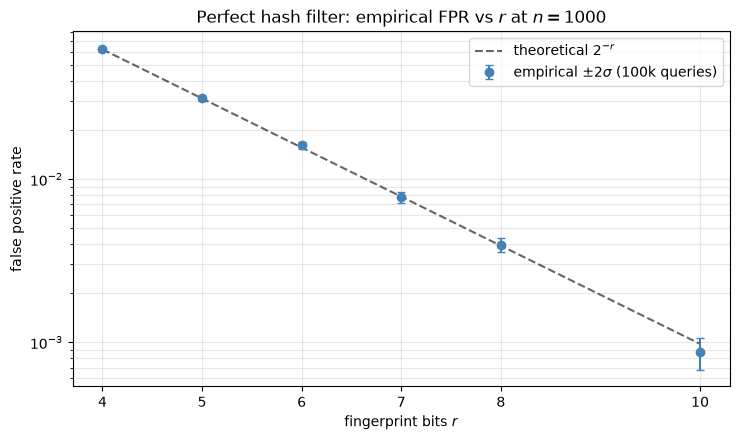

In [10]:
r_values = [4, 5, 6, 7, 8, 10]
n_sweep = 1000
n_queries_sweep = 100_000

rng_Asweep = np.random.default_rng(31415)
A_sweep = rng_Asweep.choice(10_000_000, size=n_sweep, replace=False).tolist()
A_sweep_set = set(A_sweep)
rng_qsweep = np.random.default_rng(27182)
Q_sweep = rng_qsweep.integers(low=1_000_000_000, high=1_000_000_000 + 10 * n_queries_sweep,
                              size=n_queries_sweep).tolist()
Q_sweep = [int(q) for q in Q_sweep if int(q) not in A_sweep_set]

results = []
for r_target in r_values:
    fpr_target = 2.0 ** (-r_target)
    phf_r = PerfectHashFilter(A=A_sweep, fpr=fpr_target, seed=100 + r_target)
    assert phf_r.r == r_target, f"expected r = {r_target}, got {phf_r.r}"
    # FNR check (must be zero every time).
    miss = sum(1 for a in A_sweep if not phf_r.contains(a))
    assert miss == 0, f"FNR != 0 at r = {r_target}"
    # FPR.
    fp_count = sum(1 for q in Q_sweep if phf_r.contains(q))
    emp = fp_count / len(Q_sweep)
    theo = fpr_target
    se = math.sqrt(theo * (1.0 - theo) / len(Q_sweep))
    assert abs(emp - theo) < 4 * se, f"FPR at r = {r_target} must match 2^-r"
    results.append((r_target, theo, emp, se, fp_count))
    print(f"r = {r_target:>2d}  theoretical = {theo:.6f}  empirical = {emp:.6f}  "
          f"|diff| = {abs(emp - theo):.6f}  SE = {se:.6f}  ({fp_count} FPs)")

# Plot empirical vs theoretical on a log scale.
rs = np.array([row[0] for row in results])
theos = np.array([row[1] for row in results])
emps = np.array([row[2] for row in results])
ses = np.array([row[3] for row in results])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(rs, theos, "k--", label=r"theoretical $2^{-r}$", alpha=0.6)
ax.errorbar(rs, emps, yerr=2 * ses, fmt="o", color="steelblue",
            label=r"empirical $\pm 2 \sigma$ (100k queries)",
            capsize=3, markersize=6)
ax.set_yscale("log")
ax.set_xlabel(r"fingerprint bits $r$")
ax.set_ylabel("false positive rate")
ax.set_title(f"Perfect hash filter: empirical FPR vs $r$ at $n = {n_sweep}$")
ax.set_xticks(rs)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Space: the PHF Against the Floor and the Bloom Filter

`prop:phf-space`: the perfect hash filter uses $n \lceil -\log_2 \fprate \rceil + L_\phi$ bits, and any minimal perfect hash has $L_\phi \ge n \log_2 e - O(\log n)$, so
$$L_{\text{PHF}} / n \;\ge\; \lceil -\log_2 \fprate \rceil + \log_2 e - o(1).$$
The overhead is the cost of naming each member's slot, which the floor does not require. It is **additive**, where the Bloom filter's $\log_2(1/\fprate) \cdot \log_2 e$ exceeds the floor by a **multiplicative** factor. So the PHF wins once $\fprate$ is small enough and loses at loose targets: with addressing cost $c$ bits per element, and ignoring the rounding of $r$, it beats the Bloom filter exactly when $(\log_2 e - 1) \log_2(1/\fprate) > c$, that is when $\log_2(1/\fprate) > c / 0.4427$. At the idealized $c = \log_2 e$ the break-even is near $\fprate = 2^{-3.26}$.

The first table reproduces `tab:bhf-comparison` at the idealized addressing cost. The BHF column is the expected salt length of `thm:bhf-optimality`, at most the floor, excluding $O(\log n)/n$ for parameters; it is the only column that cannot be built at these sizes.

In [11]:
def bloom_bpe(eps):
    return eb.bloom_bits_per_key(eps)          # log2(1/eps) * log2 e


def phf_bpe(eps, c):
    return eb.fingerprint_width(eps) + c       # ceil(-log2 eps) + c (prop:phf-space)


print(f"{'eps':>7}  {'floor':>6}  {'Bloom':>6}  {'BHF (expected)':>14}  {'PHF (r + log2 e)':>16}")
for eps in (1e-2, 1e-3, 1e-6):
    floor = eb.entropy_floor_bits_per_key(eps)
    print(f"{eps:>7.0e}  {floor:>6.2f}  {bloom_bpe(eps):>6.2f}  {'<= ' + format(floor, '.2f'):>14}  "
          f"{phf_bpe(eps, LOG2E):>16.2f}")
    # At the idealized addressing cost the Bloom filter is the largest in every row.
    assert floor < phf_bpe(eps, LOG2E) < bloom_bpe(eps)

assert [round(phf_bpe(e, LOG2E), 2) for e in (1e-2, 1e-3, 1e-6)] == [8.44, 11.44, 21.44]
breakeven_ideal = LOG2E / (LOG2E - 1)
print(f"\nidealized break-even (c = log2 e): log2(1/eps) = {breakeven_ideal:.2f}, eps = 2^-{breakeven_ideal:.2f}")

# n = 10^6 at eps = 1e-6: saving over Bloom at the idealized cost.
save_ideal = bloom_bpe(1e-6) - phf_bpe(1e-6, LOG2E)
print(f"n = 10^6, eps = 1e-6: idealized PHF saves {save_ideal:.1f} bits per element over Bloom, "
      f"{save_ideal * 1e6 / 8 / 1e6:.2f} MB")

    eps   floor   Bloom  BHF (expected)  PHF (r + log2 e)
  1e-02    6.64    9.59         <= 6.64              8.44
  1e-03    9.97   14.38         <= 9.97             11.44
  1e-06   19.93   28.76        <= 19.93             21.44

idealized break-even (c = log2 e): log2(1/eps) = 3.26, eps = 2^-3.26
n = 10^6, eps = 1e-6: idealized PHF saves 7.3 bits per element over Bloom, 0.91 MB


### The library filter: a real minimal perfect hash

`bernoulli.maps.PerfectFilter` is the perfect hash filter of `def:phf` with a BBHash minimal perfect hash in place of the scaffold. (The package's docstrings predate the book's correction and still call it the BHF; it is the PHF.) Its size is $c + r$ bits per key, where $c$ is the minimal perfect hash's bits per key. We build it on the same set $A$, confirm $\fnrate = 0$ and $\fprate = 2^{-r}$, read off $c$, and sweep $r$ to locate the crossover with the Bloom filter. The chapter quotes this measurement: $c = 3.23$ bits per key at $n = 1000$, so the break-even is at $\log_2(1/\fprate) \approx 7.3$; at $\fprate = 2^{-7}$ the Bloom filter is smaller ($10.10$ bits per key against $10.23$), and from $\fprate = 2^{-10}$ the PHF is ($13.23$ against $14.43$).

In [12]:
A_bytes = [str(a).encode() for a in A_main]

pf7 = PerfectFilter(A_bytes, target_fpr=target_fpr)
pf_misses = sum(1 for a in A_bytes if not pf7.contains(a))
pf_queries = [f"q:{i}".encode() for i in range(50_000)]
pf_emp_fpr = sum(1 for q in pf_queries if pf7.contains(q)) / len(pf_queries)
c_phf = pf7.bits_per_key() - pf7.fingerprint_bits()    # addressing cost, bits per key
pf_se = math.sqrt(pf7.fpr() * (1 - pf7.fpr()) / len(pf_queries))

print(f"library PerfectFilter (BBHash minimal perfect hash), n = {len(A_bytes)}, r = {pf7.fingerprint_bits()}:")
print(f"  FNR misses on members : {pf_misses}   (zero by construction)")
print(f"  empirical FPR         : {pf_emp_fpr:.5f}   (2^-r = {pf7.fpr():.5f}, SE {pf_se:.5f})")
print(f"  addressing cost       : c = {c_phf:.2f} bits/key  (>= log2 e = {LOG2E:.2f}; "
      f"the scaffold used M = n^2/2 = {phf.M:,} slots instead)")
print(f"  bits/key = r + c      : {pf7.bits_per_key():.2f}")
assert pf_misses == 0
assert abs(pf_emp_fpr - pf7.fpr()) < 4 * pf_se
assert c_phf >= LOG2E
assert round(c_phf, 2) == 3.23, "the chapter quotes c = 3.23 for this set"

breakeven = c_phf / (LOG2E - 1)
print(f"\nbreak-even: PHF < Bloom iff (log2 e - 1) log2(1/eps) > c, i.e. log2(1/eps) > {breakeven:.2f}")
print(f"  {'r':>3} {'eps':>10} {'floor':>7} {'PHF':>7} {'Bloom':>7}  winner   (predicted)")
winners = {}
for r in (4, 7, 10, 13, 16):
    pf = PerfectFilter(A_bytes, fingerprint_bits=r)
    eps = pf.fpr()
    phf_bits, bloom_bits = pf.bits_per_key(), bloom_bpe(eps)
    winner = "PHF" if phf_bits < bloom_bits else "Bloom"
    predicted = "PHF" if (LOG2E - 1) * r > c_phf else "Bloom"
    winners[r] = (winner, phf_bits, bloom_bits)
    print(f"  {r:>3} {eps:>10.2e} {eb.entropy_floor_bits_per_key(eps):>7.2f} {phf_bits:>7.2f} "
          f"{bloom_bits:>7.2f}  {winner:<7}  ({predicted})")
    assert winner == predicted, "the crossover rule must predict the winner"

assert winners[7][0] == "Bloom" and (round(winners[7][1], 2), round(winners[7][2], 2)) == (10.23, 10.10)
assert winners[10][0] == "PHF" and (round(winners[10][1], 2), round(winners[10][2], 2)) == (13.23, 14.43)

# With the measured cost the PHF is the larger structure at eps = 1e-2 (tab:bhf-comparison text).
print(f"\neps = 1e-2 with c = {c_phf:.2f}: PHF {phf_bpe(1e-2, c_phf):.2f} bits/element vs Bloom {bloom_bpe(1e-2):.2f}")
assert phf_bpe(1e-2, c_phf) > bloom_bpe(1e-2)
print(f"n = 10^6, eps = 1e-6 with BBHash addressing: saving {bloom_bpe(1e-6) - phf_bpe(1e-6, c_phf):.1f} bits per element")

library PerfectFilter (BBHash minimal perfect hash), n = 1000, r = 7:
  FNR misses on members : 0   (zero by construction)
  empirical FPR         : 0.00792   (2^-r = 0.00781, SE 0.00039)
  addressing cost       : c = 3.23 bits/key  (>= log2 e = 1.44; the scaffold used M = n^2/2 = 500,000 slots instead)
  bits/key = r + c      : 10.23

break-even: PHF < Bloom iff (log2 e - 1) log2(1/eps) > c, i.e. log2(1/eps) > 7.29
    r        eps   floor     PHF   Bloom  winner   (predicted)
    4   6.25e-02    4.00    7.23    5.77  Bloom    (Bloom)
    7   7.81e-03    7.00   10.23   10.10  Bloom    (Bloom)
   10   9.77e-04   10.00   13.23   14.43  PHF      (PHF)
   13   1.22e-04   13.00   16.23   18.76  PHF      (PHF)
   16   1.53e-05   16.00   19.23   23.08  PHF      (PHF)

eps = 1e-2 with c = 3.23: PHF 10.23 bits/element vs Bloom 9.59
n = 10^6, eps = 1e-6 with BBHash addressing: saving 5.5 bits per element


The perfect hash filter does not dominate the Bloom filter on space. It dominates at tight targets, by a margin that grows linearly in $\log_2(1/\fprate)$, and loses at loose ones, where the addressing cost is a large fraction of the budget. The crossover moves with $c$: at the idealized $c = \log_2 e$ it sits near $\fprate = 2^{-3.3}$, at BBHash's measured $3.23$ near $2^{-7.3}$. Its other advantages are not about bits: a constant number of memory probes per query, where the Bloom filter reads $k^* = \log_2(1/\fprate)$ positions.

**Closing the gap at linear build time.** The addressing cost disappears if the structure need not say *where* each member's fingerprint is, only *what* it is. A retrieval structure (a static function) stores an $r$-bit value per member and returns arbitrary values on non-members; storing $g(a)$ and accepting $x$ when the retrieved value equals $g(x)$ is an FNR-zero filter with false-positive rate $2^{-r}$ for non-members whose retrieved value is independent of $g(x)$. Dietzfelbinger and Pagh (2008) show this is achievable within a factor $1 + \delta$ of $nr$ bits; xor filters (about $1.23\,nr$), binary fuse filters, and ribbon are the practical descendants. The package's `GF2Retrieval` is a 3-segment GF(2) peeling retrieval at overhead $1.23$ plus a small additive slack for finite $n$.

In [13]:
r_ret = 7
g_salt = hashlib.sha256(b"retrieval-fingerprint").digest()


def g_ret(key: bytes) -> int:
    digest = hashlib.blake2b(key, key=g_salt[:32], digest_size=8).digest()
    return int.from_bytes(digest, "big") & ((1 << r_ret) - 1)


ret = GF2Retrieval({a: g_ret(a) for a in A_bytes}, value_bits=r_ret)
ret_misses = sum(ret.query(a) != g_ret(a) for a in A_bytes)
ret_fp = sum(ret.query(q) == g_ret(q) for q in pf_queries) / len(pf_queries)
ret_se = math.sqrt(2.0 ** -r_ret * (1 - 2.0 ** -r_ret) / len(pf_queries))

print(f"retrieval filter (GF2Retrieval), n = {len(A_bytes)}, r = {r_ret}:")
print(f"  FNR misses {ret_misses}; empirical FPR {ret_fp:.5f} (2^-r = {2.0 ** -r_ret:.5f}, SE {ret_se:.5f})")
print(f"  bits/key: retrieval {ret.bits_per_key():.2f}  <  Bloom {bloom_bpe(2.0 ** -r_ret):.2f}  "
      f"<  PHF {phf_bpe(2.0 ** -r_ret, c_phf):.2f};  floor {r_ret}")
assert ret_misses == 0
assert abs(ret_fp - 2.0 ** -r_ret) < 4 * ret_se
assert ret.bits_per_key() < bloom_bpe(2.0 ** -r_ret) < phf_bpe(2.0 ** -r_ret, c_phf)

retrieval filter (GF2Retrieval), n = 1000, r = 7:
  FNR misses 0; empirical FPR 0.00722 (2^-r = 0.00781, SE 0.00039)
  bits/key: retrieval 8.84  <  Bloom 10.10  <  PHF 10.23;  floor 7


## 9. Discussion: Two Answers to the Optimality Question

Chapter 8's floor says what an FNR-zero set must cost; chapter 14 shows what it costs to reach it.

- **The BHF meets the floor and cannot be built at scale.** One salt, found by search, with $n \log_2(1/\fprate) - 1 - \log_2 e \le \mathbb{E}[L] \le n \log_2(1/\fprate)$ and no integer rounding (§2), an exact false-positive rate $(t + 1)/N$ with independent reports across fresh non-members (§1), and an expected $\fprate^{-n}$ salts to find (§3). It is the single-seed baseline of seed search, which RecSplit and ShockHash apply to small buckets; the book uses it as the construction that shows the floor is the right target, with the build cost made explicit. Its adaptive-threshold variant does not save space: it trades recall, and its exact discrete law is a binomial tail (§4).
- **The perfect hash filter is practical and sits an additive constant above the floor.** It builds in expected linear time, has $\fnrate = 0$ and $\fprate = 2^{-r}$ (§§6 to 7), and pays $c \ge \log_2 e$ bits per element for addressing (§8). It is the standard construction of Dietzfelbinger and Pagh (2008, Sec. 1), not a new one. It beats the Bloom filter only when $(\log_2 e - 1) \log_2(1/\fprate) > c$: with the measured $c = 3.23$, the Bloom filter wins at $\fprate = 2^{-7}$ ($10.10$ against $10.23$ bits per key) and the PHF from $2^{-10}$ on.
- **Retrieval-based filters close most of the remaining gap** at linear build time (§8), and are the practical answer to the floor.

Both static constructions rebuild on every insertion, and neither merges by bit-OR (`rem:bhf-nonmergeable`): two perfect hash filters address their tables through unrelated bijections. The decision rule of §14.5 follows. For a static set where space binds, use a retrieval-based filter or a perfect hash filter, the latter only below its crossover (about $\fprate < 2^{-7}$ with BBHash addressing); for a dynamic set, use a Bloom, cuckoo, or quotient filter. The BHF itself is not on the list; it is the reference the others are measured against.

| Section | Claim | Verified |
|---------|-------|----------|
| §1 BHF | $\fnrate = 0$; FPR $= (t+1)/N$ on fresh non-members | yes (asserted) |
| §2 `thm:bhf-optimality` | series $14.67$ at $s = 2^{-16}$, $18.67$ at $2^{-20}$; bound holds; mean salt length matches the series | yes (asserted) |
| §3 build cost | mean salts tried $= \fprate^{-n}$, $n = 2, \ldots, 8$ | yes (asserted) |
| §4 `rem:adaptive-threshold` | binomial tail is exact; $\Pr[T = 0] = 3/4$ vs $1$ without replacement; covariance $3/64$; means $p/(n+1)$ | yes (asserted) |
| §§6 to 7 PHF | $\fnrate = 0$; FPR $= 2^{-r}$ for $r = 4, \ldots, 10$ | yes (asserted) |
| §8 `prop:phf-space` | $c = 3.23 \ge \log_2 e$; Bloom smaller at $2^{-7}$, PHF from $2^{-10}$; crossover rule predicts every winner | yes (asserted) |
| §8 retrieval | $8.8$ bits per key at $r = 7$, below both Bloom and PHF | yes (asserted) |

Chapter 15 reuses the perfect hash filter's skeleton with a rank in each slot instead of a fingerprint. Queried over the whole universe, that rank table still behaves like a fingerprint table; the false-positive rate becomes zero only in a restricted witness query model, and a controlled false-negative rate is then bought with a $k$-perfect hash.